In [15]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


In [16]:
def single_head_attention(Q, K, V, mask=None):
    # 获取向量维度 d_k
    d_k = Q.size(-1)
    
    # 1. Q @ K^T / sqrt(d_k) 计算缩放点积
    attn_scores = torch.matmul(Q, K.transpose(-2, -1)) / torch.sqrt(torch.tensor(d_k, dtype=torch.float32))
    
    # 2. 可选：掩码
    if mask is not None:
        attn_scores = attn_scores.masked_fill(mask == 0, -1e9)
    
    # 3. softmax得到注意力权重
    attn_weights = F.softmax(attn_scores, dim=-1)
    
    # 4. 权重乘V得到输出
    output = torch.matmul(attn_weights, V)
    
    return output, attn_weights


In [17]:
# 原始输入embedding
X = torch.randn(1, 6, 16)

# 三个可学习权重矩阵
Wq = torch.randn(16, 8)
Wk = torch.randn(16, 8)
Wv = torch.randn(16, 8)

# 原始数据 X 和权重矩阵相乘，得到Q K V
Q = torch.matmul(X, Wq)
K = torch.matmul(X, Wk)
V = torch.matmul(X, Wv)


In [19]:
# 计算注意力
output, attn_weights = single_head_attention(Q, K, V)

print("attn_scores shape:", torch.matmul(Q, K.transpose(-2,-1)).shape)
print("attn_weights shape:", attn_weights.shape)
print("output shape:", output.shape)


attn_scores shape: torch.Size([1, 6, 6])
attn_weights shape: torch.Size([1, 6, 6])
output shape: torch.Size([1, 6, 8])


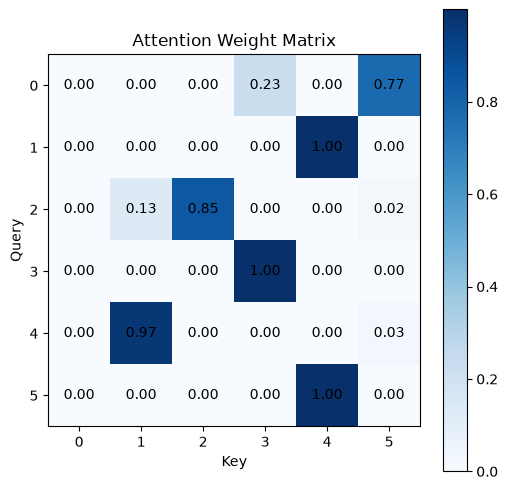

In [20]:
plt.figure(figsize=(6,6))
# 取出batch内第0个样本的权重矩阵
weight_matrix = attn_weights[0].detach().numpy#加权求和之后的特征向量，**不是注意力权重**()
plt.imshow(weight_matrix, cmap="Blues")
plt.colorbar()

# 在格子内打印数值
for i in range(seq_len):
    for j in range(seq_len):
        plt.text(j, i, f"{weight_matrix[i,j]:.2f}", ha="center", va="center")

plt.title("Attention Weight Matrix")
plt.xlabel("Key")
plt.ylabel("Query")
plt.show()
